# Pipeline de AED: Stack Overflow Developer Survey (IA/AI Agents)
## Fases 0 a 4: Hipóteses, Condicionamento, Atributos, Bivariada e Colinearidade

**Objetivo:** aplicação do pipeline integrado de Ciência de Dados sobre a Stack Overflow Developer
Survey (edição com módulo de IA/AI Agents), seguindo as diretrizes de reprodutibilidade científica
de Nina Zumel e John Mount, nas obras *Working Clean* e *No Alien Artifacts*: o pipeline de
importação, limpeza, tratamento e engenharia de atributos é 100% automatizado via código, e toda
tabela/gráfico deste notebook nasce programaticamente aqui dentro.

**Critério de parada (Timebox):** duas semanas para encerrar a fase exploratória. O sucesso não é
medido por um algoritmo finalizado, mas pela entrega de uma base condicionada (sem multicolinearidade
crítica, VIF < 5, e NAs tratados) e de um relatório documentando hipóteses fundamentadas no domínio.

## Pré-requisito: recorte de escopo do domínio (antes da Fase 0)

Antes do início do pipeline de auditoria (Fase 0 em diante), é aplicado **um único recorte de
escopo de negócio**, não relacionado a qualidade de dados/NAs/outliers: são mantidos apenas
respondentes com `MainBranch == "I am a developer by profession"`. Esse filtro define a
**população de estudo** (desenvolvedores profissionais, não estudantes/hobbistas/ex-desenvolvedores,
cujas respostas distorceriam perguntas de carreira/remuneração). Trata-se de uma decisão de design
da pesquisa, tomada antes de qualquer análise de dados; por isso, não constitui o tipo de "descarte
físico de linhas" que a Fase 0 proíbe (que trata de descarte por problemas de qualidade/NAs, tratado
somente a partir da Fase 1). A partir deste ponto, a base recortada é tratada como a "base original"
preservada intacta ao longo das Fases 0 e 1 (nenhuma linha é removida por causa de valores ausentes).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
RNG_SEED = 42


## Fase 0: Inspeção Inicial e Formulação Condicional de Hipóteses (Pré-AED)

### Passo 0.1: Raio-X de Metadados

Leitura automatizada do dicionário oficial (`survey_results_schema.csv`) e da base bruta, **sem
nenhuma alteração física**: são apenas listados colunas, formatos e tipos.

In [2]:
schema = pd.read_csv("survey_results_schema.csv")
print("Dicionário oficial, total de perguntas/colunas documentadas:", len(schema))
schema.head(10)


Dicionário oficial, total de perguntas/colunas documentadas: 139


,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0
5,QID18,TechEndorse_6,What attracts you to a technology or causes yo...,RO,Connected to an open-source project,6.0
6,QID18,TechEndorse_7,What attracts you to a technology or causes yo...,RO,Good brand and public image,7.0
7,QID18,TechEndorse_8,What attracts you to a technology or causes yo...,RO,Reliability and low latency,8.0
8,QID18,TechEndorse_9,What attracts you to a technology or causes yo...,RO,Costs are manageable,9.0
9,QID18,TechEndorse_13,What attracts you to a technology or causes yo...,RO,Other (please specify):,10.0


In [3]:
# Raio-X das colunas brutas (172 colunas), sem carregar o arquivo inteiro em memória:
# usa-se apenas o cabeçalho para o metadado físico (nomes de colunas).
raw_header = pd.read_csv("survey_results_public.csv", nrows=0)
print("Total de colunas na base bruta:", len(raw_header.columns))


Total de colunas na base bruta: 172


In [4]:
COLS = [
    "ResponseId", "MainBranch",
    "Age", "EdLevel", "Employment", "WorkExp", "YearsCode", "DevType", "OrgSize",
    "ICorPM", "RemoteWork", "Country", "Industry", "JobSat", "ConvertedCompYearly",
    "AIThreat", "AISelect", "AISent", "AIAcc", "AIComplex", "AIAgents", "SOVisitFreq",
]

df_raw = pd.read_csv("survey_results_public.csv", usecols=COLS, na_values=["NA"], low_memory=False)
print("Linhas na base bruta:", len(df_raw))

# Recorte de escopo do domínio (ver célula de abertura): único ponto do notebook em que
# linhas são removidas antes da Fase 1; não é descarte por NAs/outliers.
df = df_raw[df_raw["MainBranch"] == "I am a developer by profession"].drop(columns=["MainBranch"]).reset_index(drop=True)
print("Linhas após recorte de escopo (devs profissionais):", len(df))

CONTINUOUS = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly"]
for c in CONTINUOUS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("\nTipos de dados (Raio-X pós seleção de colunas de resposta única):")
df.dtypes


Linhas na base bruta: 49191
Linhas após recorte de escopo (devs profissionais): 37467

Tipos de dados (Raio-X pós seleção de colunas de resposta única):


ResponseId               int64
Age                        str
EdLevel                    str
Employment                 str
WorkExp                float64
YearsCode              float64
DevType                    str
OrgSize                    str
ICorPM                     str
RemoteWork                 str
Industry                   str
AIThreat                   str
Country                    str
SOVisitFreq                str
AISelect                   str
AISent                     str
AIAcc                      str
AIComplex                  str
AIAgents                   str
ConvertedCompYearly    float64
JobSat                 float64
dtype: object

**Colunas descartadas do pipeline (Fase 0, critério de dados administrativos/controle):**
`ResponseId` é mantida apenas como **identificador de linha** (chave sequencial); não é utilizada
como preditor em nenhuma etapa estatística a partir daqui. É o único caso análogo a "ID de
controle" citado no roteiro. Nenhuma outra coluna do subconjunto é 100% constante ou puramente
administrativa.

As demais 151 colunas da base bruta (de 172) já haviam sido descartadas na definição do escopo do
trabalho (documentado em `descricao_base_dados.txt`): a maioria são perguntas de múltipla escolha ou
de ranking composto (valores separados por `;`), fora do escopo desta AED de variáveis de resposta
única.

### Passo 0.2: O Teste do Rótulo

Verifica-se se a base possui uma coluna representativa de desfecho (variável dependente).

In [5]:
print(df["AIAgents"].value_counts(dropna=False))
print("\nProporção de nulos em AIAgents:", round(df['AIAgents'].isna().mean()*100, 1), "%")


AIAgents
NaN                                                      12684
No, and I don't plan to                                   9091
No, but I plan to                                         4272
Yes, I use AI agents at work daily                        3692
No, I use AI exclusively in copilot/autocomplete mode     3524
Yes, I use AI agents at work weekly                       2289
Yes, I use AI agents at work monthly or infrequently      1915
Name: count, dtype: int64

Proporção de nulos em AIAgents: 33.9 %


**Decisão formal: Caminho A (Supervisionado).**

A coluna `AIAgents` ("uso de agentes de IA no trabalho") constitui uma variável de desfecho
legítima: é o tema central desta edição da pesquisa (módulo específico sobre IA e AI Agents) e tem
relevância de negócio direta, já que entender **quem adota agentes de IA e por quê** orienta
decisões de produto, treinamento e go-to-market de ferramentas de IA para desenvolvedores.

O rótulo original (6 categorias) é simplificado em uma variável binária `AIAgents_bin`, pelos
motivos a seguir:
- Facilita a aplicação dos testes bivariados corretos da Fase 3 (Wilcoxon/t-test exigem 2 grupos).
- As 6 categorias já expressam claramente duas famílias: **usa** ("... daily/weekly/monthly or
  infrequently") vs. **não usa** ("No, and I don't plan to" / "No, I use AI exclusively in
  copilot/autocomplete mode" / "No, but I plan to").

**Teste de variância do alvo:** a tabela acima mostra 2 classes não degeneradas (nem classe única,
nem variância nula); `AIAgents_bin` atende, assim, ao critério de descarte de hipóteses preditivas
do Passo 0.2 (rejeição só ocorreria se o alvo não tivesse variabilidade).

**Nulos do rótulo (33.9%):** diferente de nulos em preditores (tratados via `isBAD` na Fase 1), um
rótulo ausente **não pode ser imputado** sem inventar a resposta que se deseja prever, o que
configura uma exceção justificada e amplamente aceita em aprendizado supervisionado. Por isso,
linhas com `AIAgents` nulo são preservadas na base condicionada (Fases 1 e 2, para qualquer uso
exploratório/não supervisionado futuro), mas **excluídas apenas do subconjunto rotulado** usado nos
testes bivariados e na modelagem supervisionada (Fases 3 a 5).

In [6]:
def to_ai_agents_bin(s):
    yes = {
        "Yes, I use AI agents at work daily",
        "Yes, I use AI agents at work weekly",
        "Yes, I use AI agents at work monthly or infrequently",
    }
    no = {
        "No, and I don't plan to",
        "No, I use AI exclusively in copilot/autocomplete mode",
        "No, but I plan to",
    }
    return s.map(lambda v: 1 if v in yes else (0 if v in no else np.nan))

df["AIAgents_bin"] = to_ai_agents_bin(df["AIAgents"])
print(df["AIAgents_bin"].value_counts(dropna=False))
print("\nBase rotulada (rótulo não nulo):", df["AIAgents_bin"].notna().sum(), "linhas")


AIAgents_bin
0.0    16887
NaN    12684
1.0     7896
Name: count, dtype: int64

Base rotulada (rótulo não nulo): 24783 linhas


### Passo 0.3: Guia de Hipóteses (Caminho A)

Hipóteses causais formais **X → Y**, com `Y = AIAgents_bin` (uso de agentes de IA no trabalho),
amparadas no domínio (adoção de ferramentas por desenvolvedores profissionais). Cada hipótese já
indica o teste estatístico esperado na Fase 3, dado que nenhuma variável contínua é normal (ver
Fase 1: todas rejeitam Shapiro-Wilk), exigindo estatísticas não-paramétricas.

| ID | Hipótese inicial | Preditor(es) (X) | Teste esperado (Fase 3) |
|---|---|---|---|
| H1 | Desenvolvedores mais experientes (maior `WorkExp`/`YearsCode`) apresentam **menor** probabilidade de uso de agentes de IA, refletindo adoção mais cautelosa e menor necessidade percebida em comparação a devs juniores. | `WorkExp`, `YearsCode` (contínuas) | Wilcoxon/Mann-Whitney (2 grupos) |
| H2 | O uso de agentes de IA está associado ao cargo/função (`DevType`) e ao tamanho da empresa (`OrgSize`), com maior adoção esperada em funções mais técnicas e empresas maiores/mais estruturadas. | `DevType`, `OrgSize` (categóricas) | Qui-Quadrado / Fisher |
| H3 | Maior confiança na precisão da IA (`AIAcc`) e melhor percepção de desempenho em tarefas complexas (`AIComplex`) associam-se a **maior** probabilidade de uso de agentes de IA. | `AIAcc`, `AIComplex` (categóricas ordinais) | Qui-Quadrado / Fisher |
| H4 | A satisfação no cargo (`JobSat`) está associada ao uso de agentes de IA (hipótese de produtividade percebida). | `JobSat` (contínua) | Wilcoxon/Mann-Whitney |
| H5 | O modelo de trabalho (`RemoteWork`) e o papel (`ICorPM`) estão associados à adoção, sob a hipótese de que trabalho remoto e contribuidores individuais adotam mais (uso mais autônomo de ferramentas). | `RemoteWork`, `ICorPM` (categóricas) | Qui-Quadrado / Fisher |
| H6 | Maior frequência de visita ao Stack Overflow (`SOVisitFreq`) associa-se a **menor** uso de agentes de IA, com a comunidade tradicional funcionando como substituto parcial. | `SOVisitFreq` (categórica ordinal) | Qui-Quadrado / Fisher |

**Critério de descarte de hipóteses aplicado neste ponto:** nenhuma das hipóteses acima depende de
preditor ausente da base ou de proxy excessivamente fraca; todas as variáveis citadas existem no
subconjunto de 20 colunas selecionado.

**Exploração secundária (fora do escopo formal de H1 a H6, não testada com o rigor do Caminho A):**
`AIThreat`, `AISent` e `ConvertedCompYearly` também apresentam relação plausível com adoção de IA,
mas a manutenção de um único alvo (`AIAgents_bin`) evita diluir o timebox de duas semanas em
múltiplos pipelines de rótulo. Trata-se de um critério de parada justificado pelas hipóteses
definidas, não apenas pelo tempo.

**Descarte por redundância/vazamento (leakage):** `AISelect` ("uso de ferramentas de IA no
desenvolvimento") é descartada do conjunto de preditores. Embora não seja idêntica ao rótulo, é uma
proxy quase direta: "usar ferramentas de IA" é quase uma pré-condição de "usar agentes de IA", o
que tornaria qualquer associação estatisticamente óbvia e pouco informativa (tautologia), violando
a diretriz de evitar obviedades estatísticas.

In [7]:
df = df.drop(columns=["AISelect"])
CATEGORICAL = [c for c in df.columns if c not in CONTINUOUS + ["ResponseId", "AIAgents", "AIAgents_bin"]]
print("Preditores categóricos remanescentes:", CATEGORICAL)


Preditores categóricos remanescentes: ['Age', 'EdLevel', 'Employment', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'Industry', 'AIThreat', 'Country', 'SOVisitFreq', 'AISent', 'AIAcc', 'AIComplex']


## Fase 1: Análise Univariada e Condicionamento de Dados (Data Conditioning)

Nesta fase: (1) a normalidade é testada formalmente com Shapiro-Wilk; (2) inconsistências físicas
são convertidas em NA e outliers extremos são isolados e também convertidos em NA; (3) todos os NAs
(originais e gerados por outliers) são tratados cientificamente pelo método **isBAD**, sem nenhum
descarte ingênuo de linhas (`complete cases`).

### Normalidade (Shapiro-Wilk)

O teste de Shapiro-Wilk é recomendado para amostras de até ~5.000 observações (acima disso a
estatística fica pouco sensível e o p-valor tende a rejeitar quase qualquer desvio mínimo da
normalidade). Por isso o teste é executado em uma amostra aleatória de até 5.000 observações por
variável (`random_state=42`, reprodutível), acompanhado de gráficos de densidade sobre a
distribuição completa.

In [8]:
def shapiro_sample(s, n=5000, seed=RNG_SEED):
    s = s.dropna()
    if len(s) > n:
        s = s.sample(n, random_state=seed)
    stat, p = stats.shapiro(s)
    return pd.Series({"n_testado": len(s), "estatistica_W": round(stat, 4), "p_valor": p,
                       "eh_normal_alpha_0.05": "Sim" if p >= 0.05 else "Não"})

shapiro_report = pd.DataFrame({c: shapiro_sample(df[c]) for c in CONTINUOUS}).T
shapiro_report


,n_testado,estatistica_W,p_valor,eh_normal_alpha_0.05
WorkExp,5000,0.8778,0.0,Não
YearsCode,5000,0.9225,0.0,Não
JobSat,5000,0.9116,0.0,Não
ConvertedCompYearly,5000,0.1212,0.0,Não


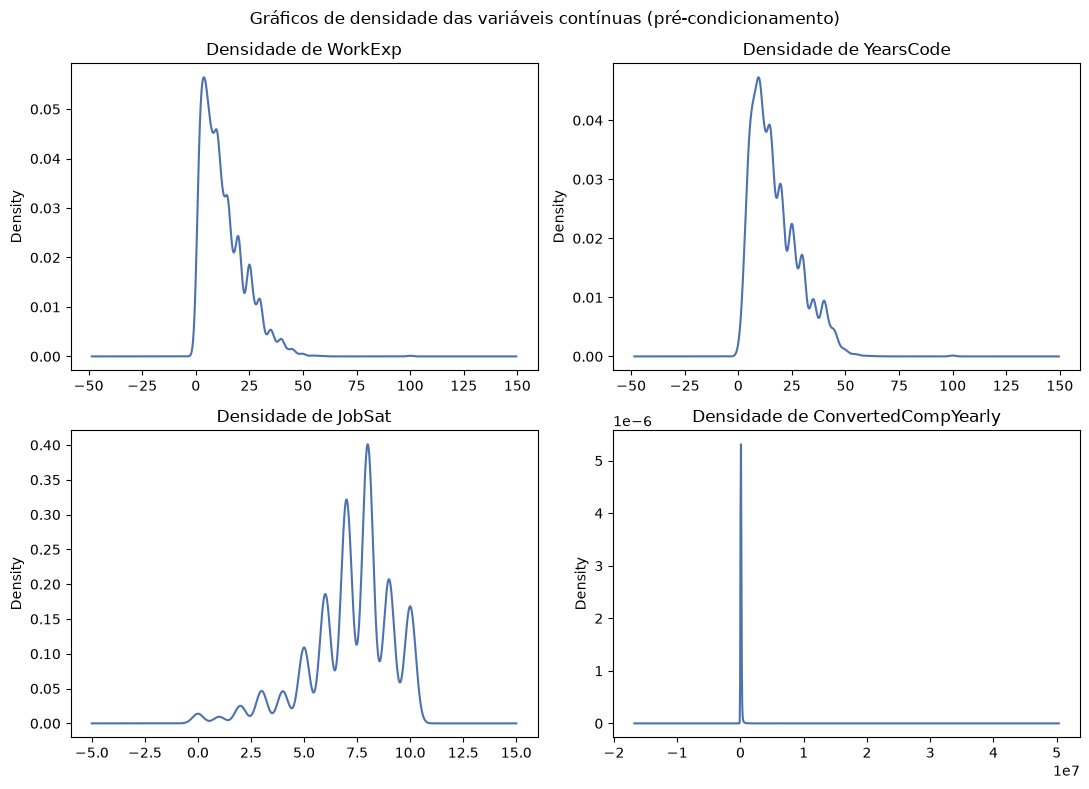

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, c in zip(axes.flat, CONTINUOUS):
    df[c].dropna().plot(kind="density", ax=ax, color="#4C72B0")
    ax.set_title(f"Densidade de {c}")
plt.suptitle("Gráficos de densidade das variáveis contínuas (pré-condicionamento)")
plt.tight_layout()
plt.show()


**H0 rejeitada (p < 0.05) para as 4 variáveis contínuas.** Nenhuma segue distribuição
normal de Gauss, o que confirma, já na Fase 1, que os testes bivariados da Fase 3 devem ser
**não-paramétricos baseados em postos** (Wilcoxon/Mann-Whitney), conforme já antecipado nas
hipóteses H1 e H4 da Fase 0.

### Inconsistências físicas e outliers extremos

Primeiramente, é convertido em NA qualquer valor que viole regras físicas do domínio
(idade/experiência/remuneração negativas, `JobSat` fora da escala de 0 a 10 da pesquisa). Em
seguida, outliers de medição extremos são isolados via IQR (limiar de 3×IQR, seguindo a convenção
de "outlier extremo" de Tukey, mais conservadora que o 1,5×IQR de "outlier comum", de modo a não
descartar informação demais em variáveis já sabidamente assimétricas) e também convertidos em NA, a
serem tratados no mesmo pipeline isBAD.

In [10]:
# 1) Violações de regra física -> NA
n_antes = {c: df[c].notna().sum() for c in CONTINUOUS}

invalid_mask = pd.DataFrame({
    "WorkExp": df["WorkExp"] < 0,
    "YearsCode": df["YearsCode"] < 0,
    "JobSat": (df["JobSat"] < 0) | (df["JobSat"] > 10),
    "ConvertedCompYearly": df["ConvertedCompYearly"] <= 0,
})
for c in CONTINUOUS:
    n_flag = invalid_mask[c].sum()
    df.loc[invalid_mask[c], c] = np.nan
    print(f"{c}: {n_flag} valores fisicamente inválidos convertidos em NA")


WorkExp: 0 valores fisicamente inválidos convertidos em NA
YearsCode: 0 valores fisicamente inválidos convertidos em NA
JobSat: 0 valores fisicamente inválidos convertidos em NA
ConvertedCompYearly: 0 valores fisicamente inválidos convertidos em NA


In [11]:
# 2) Outliers extremos (3x IQR) -> NA
def extreme_outlier_mask(s, k=3.0):
    s_valid = s.dropna()
    q1, q3 = s_valid.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return (s < low) | (s > high), low, high

outlier_report_rows = []
for c in CONTINUOUS:
    mask, low, high = extreme_outlier_mask(df[c])
    mask = mask.fillna(False)
    outlier_report_rows.append({
        "variável": c, "limite_inf": round(low, 2), "limite_sup": round(high, 2),
        "n_outliers_extremos": int(mask.sum()),
        "% da base": round(100 * mask.sum() / len(df), 2),
    })
    df.loc[mask, c] = np.nan

outlier_report = pd.DataFrame(outlier_report_rows)
outlier_report


,variável,limite_inf,limite_sup,n_outliers_extremos,% da base
0,WorkExp,-37.0,61.0,18,0.05
1,YearsCode,-39.0,73.0,21,0.06
2,JobSat,0.0,14.0,0,0.00
3,ConvertedCompYearly,-204985.0,370789.5,292,0.78


### Tratamento científico de NAs pelo método `isBAD`

Regra aplicada por variável (conforme diretriz):
- **Taxa de ausência menor que 2%**: remoção física de linha é permitida (perda desprezível).
  Aplica-se a `Age` (0%), `EdLevel` (1,8%) e `Employment` (1,5%), as três únicas variáveis do
  subconjunto abaixo do limiar.
- **Taxa de ausência de 2% ou mais**: os dados são mantidos e condicionados. Categóricas recebem o
  nível literal `'missing'`. Numéricas recebem imputação pela **mediana** (mais robusta que a
  média, dado que nenhuma variável contínua é normal) e ganham uma coluna booleana indicadora
  `<var>_isBAD` (`True` = valor foi alterado; `False` = valor original preservado). Os NAs
  originais e os gerados pela etapa de outliers acima entram juntos nesse mesmo tratamento.

In [12]:
# Linhas removidas (variáveis com < 2% de nulo)
LOW_NULL_DROP = ["Age", "EdLevel", "Employment"]
n_antes_drop = len(df)
null_pct_low = {c: round(100 * df[c].isna().mean(), 2) for c in LOW_NULL_DROP}
print("% nulos nas variáveis candidatas à remoção de linha:", null_pct_low)

df = df.dropna(subset=LOW_NULL_DROP).reset_index(drop=True)
print(f"\nLinhas antes: {n_antes_drop} | depois da remoção (<2% nulo): {len(df)} "
      f"({n_antes_drop - len(df)} linhas removidas, {round(100*(n_antes_drop-len(df))/n_antes_drop, 2)}%)")


% nulos nas variáveis candidatas à remoção de linha: {'Age': np.float64(0.0), 'EdLevel': np.float64(1.76), 'Employment': np.float64(1.52)}

Linhas antes: 37467 | depois da remoção (<2% nulo): 36808 (659 linhas removidas, 1.76%)


In [13]:
# isBAD, numéricas: imputação pela mediana + coluna indicadora
isbad_report = []
for c in CONTINUOUS:
    pct_null = round(100 * df[c].isna().mean(), 2)
    median_val = df[c].median()
    df[f"{c}_isBAD"] = df[c].isna()
    df[c] = df[c].fillna(median_val)
    isbad_report.append({"variável": c, "% nulo tratado": pct_null,
                          "valor de imputação (mediana)": round(median_val, 2),
                          "n_isBAD": int(df[f'{c}_isBAD'].sum())})

pd.DataFrame(isbad_report)


,variável,% nulo tratado,valor de imputação (mediana),n_isBAD
0,WorkExp,5.24,10.0,1929
1,YearsCode,9.48,15.0,3489
2,JobSat,27.61,8.0,10162
3,ConvertedCompYearly,45.96,76334.0,16916


In [14]:
# isBAD, categóricas com >=2% de nulo: nível literal 'missing'
CATEGORICAL_MISSING = [c for c in CATEGORICAL if c not in LOW_NULL_DROP]
for c in CATEGORICAL_MISSING:
    df[c] = df[c].fillna("missing")

null_final = df.drop(columns=["ResponseId"]).isna().mean().sort_values(ascending=False)
print("Nulos remanescentes após condicionamento (deve ser 0 em tudo, exceto AIAgents/AIAgents_bin, o rótulo):")
null_final[null_final > 0]


Nulos remanescentes após condicionamento (deve ser 0 em tudo, exceto AIAgents/AIAgents_bin, o rótulo):


AIAgents        0.327483
AIAgents_bin    0.327483
dtype: float64

Os únicos nulos remanescentes são do **rótulo** (`AIAgents` / `AIAgents_bin`),
propositalmente não imputados (ver justificativa na Fase 0, Passo 0.2). Todos os preditores
encontram-se 100% condicionados, sem nenhuma linha descartada por causa de NAs além das permitidas
pela regra dos 2%.

## Fase 2: Engenharia de Atributos (Feature Engineering)

São aplicadas transformações matemáticas nas numéricas e encodings nas categóricas, respeitando a
cardinalidade de cada uma e a proibição de Target Encoding fora do Caminho A (não aplicável aqui,
pois o trabalho segue o Caminho A).

### Transformações matemáticas

- **log10** em `ConvertedCompYearly` (dado monetário, altamente assimétrico mesmo após o tratamento
  de outliers extremos), gerando `ConvertedCompYearly_log`.
- **Z-score** em todas as numéricas (incluindo a versão log de remuneração), pois a padronização
  por escala é crítica para qualquer algoritmo baseado em distância geométrica (ex.: K-Means, KNN)
  e também estabiliza modelos lineares regularizados (Ridge/Lasso).

In [15]:
df["ConvertedCompYearly_log"] = np.log10(df["ConvertedCompYearly"])

Z_SOURCE = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly_log"]
for c in Z_SOURCE:
    mu, sigma = df[c].mean(), df[c].std()
    df[f"{c}_z"] = (df[c] - mu) / sigma

df[[*Z_SOURCE, *[f"{c}_z" for c in Z_SOURCE]]].describe().T[["mean", "std", "min", "max"]]


,mean,std,min,max
WorkExp,1.273182e+01,9.573520,1.000000,60.000000
YearsCode,1.707178e+01,10.376139,1.000000,68.000000
JobSat,7.422979e+00,1.735394,0.000000,10.000000
ConvertedCompYearly_log,4.802931e+00,0.461874,0.000000,5.568202
WorkExp_z,2.470916e-17,1.000000,-1.225445,4.937387
YearsCode_z,-9.265934e-17,1.000000,-1.548917,4.908206
JobSat_z,1.096469e-16,1.000000,-4.277403,1.484978
ConvertedCompYearly_log_z,1.084114e-15,1.000000,-10.398792,1.656883


### Encodings

- **Dummy / One-Hot** para categóricas de baixa cardinalidade (até 10 categorias), com **descarte
  do primeiro nível de cada grupo** (`drop_first=True`). Essa escolha evita a "armadilha das
  dummies" (uma categoria é sempre a soma exata das demais do mesmo grupo, o que geraria VIF
  infinito trivial e não informativo na auditoria de colinearidade da Fase 4).
- **Target Encoding (Impact Coding) com suavização de Laplace** para as de alta cardinalidade
  (`DevType`, `Country`, `Industry`), permitido por se tratar do Caminho A. O encoding é ajustado
  **apenas no subconjunto rotulado** (`AIAgents_bin` não nulo), para não incorrer em vazamento de
  informação de linhas sem rótulo, sendo depois aplicado a toda a base (categorias sem estatística
  suficiente convergem para a média global, via o termo de suavização `m`).

> **Nota de ressalva metodológica:** trata-se de um target encoding "global" (ajustado uma única
> vez em todo o conjunto rotulado), adequado a esta fase exploratória de engenharia de atributos.
> Caso o pipeline avance para treino/avaliação de modelo preditivo, o encoding deve ser recalculado
> **por fold** (K-fold target encoding) para evitar vazamento entre treino e teste. Este ponto
> permanece registrado como item pendente para a fase de modelagem, fora do escopo desta AED.

In [16]:
cardinality = {c: df[c].nunique() for c in CATEGORICAL}
LOW_CARD = [c for c, n in cardinality.items() if n <= 10]
HIGH_CARD = [c for c, n in cardinality.items() if n > 10]
print("Baixa cardinalidade (dummy):", LOW_CARD)
print("Alta cardinalidade (target encoding):", HIGH_CARD, {c: cardinality[c] for c in HIGH_CARD})


Baixa cardinalidade (dummy):

 ['Age', 'EdLevel', 'Employment', 'OrgSize', 'ICorPM', 'RemoteWork', 'AIThreat', 'SOVisitFreq', 'AISent', 'AIAcc', 'AIComplex']
Alta cardinalidade (target encoding): ['DevType', 'Industry', 'Country'] {'DevType': 33, 'Industry': 16, 'Country': 169}


In [17]:
df_dummies = pd.get_dummies(df[LOW_CARD], prefix=LOW_CARD, drop_first=True)
print("Colunas dummy geradas:", df_dummies.shape[1])
df = pd.concat([df, df_dummies], axis=1)
df_dummies.columns.tolist()[:10]


Colunas dummy geradas:

 61


['Age_25-34 years old',
 'Age_35-44 years old',
 'Age_45-54 years old',
 'Age_55-64 years old',
 'Age_65 years or older',
 'Age_Prefer not to say',
 'EdLevel_Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
 'EdLevel_Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
 'EdLevel_Other (please specify):',
 'EdLevel_Primary/elementary school']

In [18]:
def target_encode(series, target, m=10):
    fit_mask = target.notna()
    global_mean = target[fit_mask].mean()
    agg = pd.DataFrame({"y": target[fit_mask], "x": series[fit_mask]}).groupby("x")["y"].agg(["mean", "count"])
    smooth = (agg["count"] * agg["mean"] + m * global_mean) / (agg["count"] + m)
    encoded = series.map(smooth).fillna(global_mean)
    return encoded, smooth, global_mean

target_encoding_maps = {}
for c in HIGH_CARD:
    encoded, mapping, global_mean = target_encode(df[c], df["AIAgents_bin"], m=10)
    df[f"{c}_target_enc"] = encoded
    target_encoding_maps[c] = mapping
    print(f"{c}: {len(mapping)} categorias codificadas, média global de fallback = {round(global_mean, 4)}")


DevType: 32 categorias codificadas, média global de fallback = 0.3187
Industry: 16 categorias codificadas, média global de fallback = 0.3187
Country: 167 categorias codificadas, média global de fallback = 0.3187


In [19]:
print("Top 5 categorias de DevType por taxa suavizada de uso de agentes de IA:")
target_encoding_maps["DevType"].sort_values(ascending=False).head(5)


Top 5 categorias de DevType por taxa suavizada de uso de agentes de IA:


x
Developer, AI apps or physical AI       0.542965
Founder, technology or otherwise        0.477391
Project manager                         0.469159
AI/ML engineer                          0.467644
Senior executive (C-suite, VP, etc.)    0.457629
dtype: float64

### Estado da base ao final da Fase 2

A base encontra-se condicionada e com atributos projetados: todos os preditores estão sem valores
ausentes (à exceção do rótulo, propositalmente preservado), as numéricas estão padronizadas e as
categóricas codificadas. Está pronta, portanto, para a análise bivariada/multivariada.

In [20]:
print("Shape da base ao final da Fase 2:", df.shape)


Shape da base ao final da Fase 2: (36808, 94)


## Fase 3: Análise Bivariada / Multivariada (Foco em Descoberta e Validação)

O trabalho segue o **Caminho A**: é avaliado o poder preditivo individual de cada preditor de
H1 a H6 contra o alvo `AIAgents_bin`, utilizando apenas o subconjunto **rotulado** (linhas com
`AIAgents` não nulo, ver justificativa na Fase 0). Como nenhuma variável contínua é normal
(Shapiro-Wilk, Fase 1), utiliza-se **Wilcoxon/Mann-Whitney** para contínua-vs-binária. Para
categórica-vs-categórica, utiliza-se **Qui-Quadrado de independência** (agrupando categorias raras
em "Outros" quando a variável tem muitas categorias, de modo a manter frequências esperadas válidas
no teste). São filtradas evidências com p < 0.05.

In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [22]:
df_lab = df[df["AIAgents_bin"].notna()].copy()
df_lab["AIAgents_bin"] = df_lab["AIAgents_bin"].astype(int)
print("Base rotulada para os testes bivariados:", df_lab.shape)


Base rotulada para os testes bivariados: (24754, 94)


In [23]:
def mannwhitney_test(col):
    g1 = df_lab.loc[df_lab["AIAgents_bin"] == 1, col]
    g0 = df_lab.loc[df_lab["AIAgents_bin"] == 0, col]
    stat, p = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    return {
        "variável": col, "teste": "Mann-Whitney U",
        "mediana_usa_agentes": round(g1.median(), 2), "mediana_nao_usa": round(g0.median(), 2),
        "estatística": round(stat, 1), "p_valor": p,
    }

def chi2_test(col, top_n=15):
    s = df_lab[col]
    if s.nunique() > top_n:
        top = s.value_counts().nlargest(top_n).index
        s = s.where(s.isin(top), "Outros_agrupado")
    table = pd.crosstab(s, df_lab["AIAgents_bin"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    return {
        "variável": col, "teste": "Qui-Quadrado", "n_categorias_testadas": table.shape[0],
        "estatística": round(chi2, 1), "p_valor": p,
    }

HYPOTHESIS_TESTS = {
    "H1": [mannwhitney_test("WorkExp"), mannwhitney_test("YearsCode")],
    "H2": [chi2_test("DevType"), chi2_test("OrgSize")],
    "H3": [chi2_test("AIAcc"), chi2_test("AIComplex")],
    "H4": [mannwhitney_test("JobSat")],
    "H5": [chi2_test("RemoteWork"), chi2_test("ICorPM")],
    "H6": [chi2_test("SOVisitFreq")],
}

rows = []
for h, tests in HYPOTHESIS_TESTS.items():
    for t in tests:
        t = dict(t)
        t["hipótese"] = h
        t["significativo (p<0.05)"] = t["p_valor"] < 0.05
        rows.append(t)

bivariate_report = pd.DataFrame(rows)[
    ["hipótese", "variável", "teste", "estatística", "p_valor", "significativo (p<0.05)"]
]
bivariate_report


,hipótese,variável,teste,estatística,p_valor,significativo (p<0.05)
0,H1,WorkExp,Mann-Whitney U,64854424.5,1.421806e-03,True
1,H1,YearsCode,Mann-Whitney U,61988996.0,4.555230e-18,True
2,H2,DevType,Qui-Quadrado,346.1,1.358468e-64,True
3,H2,OrgSize,Qui-Quadrado,43.6,1.642955e-06,True
4,H3,AIAcc,Qui-Quadrado,1748.5,0.000000e+00,True
5,H3,AIComplex,Qui-Quadrado,2819.4,0.000000e+00,True
6,H4,JobSat,Mann-Whitney U,69958538.0,2.263310e-11,True
7,H5,RemoteWork,Qui-Quadrado,44.3,2.030992e-08,True
8,H5,ICorPM,Qui-Quadrado,141.1,2.337613e-31,True
9,H6,SOVisitFreq,Qui-Quadrado,390.1,3.152623e-80,True


### Filtro de evidências e descarte físico

Preditores com p ≥ 0.05 contra o alvo são descartados fisicamente do conjunto de preditores que
avança para a Fase 4 (colinearidade). Apenas atributos estatisticamente significativos avançam.

In [24]:
SIGNIFICANT_PREDICTORS = bivariate_report.loc[bivariate_report["p_valor"] < 0.05, "variável"].tolist()
DROPPED_FASE3 = bivariate_report.loc[bivariate_report["p_valor"] >= 0.05, "variável"].tolist()
print("Preditores significativos (avançam para Fase 4):", SIGNIFICANT_PREDICTORS)
print("Preditores descartados (p >= 0.05):", DROPPED_FASE3)


Preditores significativos (avançam para Fase 4): ['WorkExp', 'YearsCode', 'DevType', 'OrgSize', 'AIAcc', 'AIComplex', 'JobSat', 'RemoteWork', 'ICorPM', 'SOVisitFreq']
Preditores descartados (p >= 0.05): []


### Diagnóstico de viés por subgrupo (cuidado indicado no roteiro)

Antes da aceitação de um preditor categórico como relevante, verifica-se se sua associação não
decorre de um subgrupo minoritário disperso demais (contagem esperada muito baixa nalguma célula),
o que infla o Qui-Quadrado artificialmente. É reportada a menor contagem esperada de cada teste
categórico significativo; valores abaixo de 5 pedem cautela na leitura causal.

In [25]:
def min_expected_count(col, top_n=15):
    s = df_lab[col]
    if s.nunique() > top_n:
        top = s.value_counts().nlargest(top_n).index
        s = s.where(s.isin(top), "Outros_agrupado")
    table = pd.crosstab(s, df_lab["AIAgents_bin"])
    _, _, _, expected = stats.chi2_contingency(table)
    return expected.min()

cat_significant = [v for v in SIGNIFICANT_PREDICTORS if v not in ("WorkExp", "YearsCode", "JobSat")]
pd.DataFrame({
    "variável": cat_significant,
    "menor_contagem_esperada": [round(min_expected_count(v), 1) for v in cat_significant],
})


,variável,menor_contagem_esperada
0,DevType,85.1
1,OrgSize,124.6
2,AIAcc,33.5
3,AIComplex,28.7
4,RemoteWork,855.4
5,ICorPM,868.8
6,SOVisitFreq,156.5


## Fase 4: Análise de Colinearidade e Multicolinearidade (Tratamento)

O Fator de Inflação da Variância (VIF) é calculado para os preditores sobreviventes da Fase 3, já
projetados (dummy/target encoding da Fase 2 + Z-score). O limiar de exclusão é **VIF > 5**. Por se
tratar do Caminho A, a colinearidade afeta principalmente a estabilidade de modelos
lineares/logísticos; ainda assim, o VIF é tratado para manter a explicabilidade limpa (recomendado
mesmo para modelos de árvore).

In [26]:
def feature_columns_for(var):
    if var in ("WorkExp", "YearsCode", "JobSat"):
        return [f"{var}_z"]
    if var in HIGH_CARD:
        return [f"{var}_target_enc"]
    return [c for c in df.columns if c.startswith(f"{var}_") and c in df_dummies.columns]

vif_features = []
for v in SIGNIFICANT_PREDICTORS:
    vif_features += feature_columns_for(v)
vif_features = sorted(set(vif_features))
print("Colunas do design matrix para VIF:", len(vif_features))

X_vif = df_lab[vif_features].astype(float)
X_vif = X_vif.assign(const=1.0)


Colunas do design matrix para VIF: 38


In [27]:
def compute_vif(X):
    cols = [c for c in X.columns if c != "const"]
    return pd.DataFrame({
        "variável": cols,
        "VIF": [variance_inflation_factor(X.values, X.columns.get_loc(c)) for c in cols],
    }).sort_values("VIF", ascending=False)

vif_report = compute_vif(X_vif)
vif_report


,variável,VIF
28,RemoteWork_missing,28.967236
23,OrgSize_missing,20.617369
13,ICorPM_missing,12.158095
36,WorkExp_z,5.070114
37,YearsCode_z,5.054613
3,AIAcc_Somewhat trust,2.739570
17,OrgSize_20 to 99 employees,2.266030
16,OrgSize_100 to 499 employees,2.162169
26,RemoteWork_Remote,2.120904
1,AIAcc_Neither trust nor distrust,2.110533


### Regra de corte do VIF (iterativa)

A variável com maior VIF > 5 é removida uma a uma, recalculando-se a cada rodada, até que todas as
sobreviventes apresentem VIF ≤ 5. Esse procedimento evita a remoção em bloco de variáveis cuja
colinearidade era causada por uma única redundante.

In [28]:
X_iter = X_vif.copy()
removed_vif = []
while True:
    rep = compute_vif(X_iter)
    worst = rep.iloc[0]
    if worst["VIF"] <= 5:
        break
    removed_vif.append({"variável": worst["variável"], "VIF_no_momento_da_remoção": round(worst["VIF"], 2)})
    X_iter = X_iter.drop(columns=[worst["variável"]])

final_vif = compute_vif(X_iter)
print("Removidas por VIF > 5:")
display(pd.DataFrame(removed_vif)) if removed_vif else print("(nenhuma)")
print("\nVIF final (todas <= 5):")
final_vif


Removidas por VIF > 5:


,variável,VIF_no_momento_da_remoção
0,RemoteWork_missing,28.97
1,OrgSize_missing,9.66
2,WorkExp_z,5.07



VIF final (todas <= 5):


,variável,VIF
3,AIAcc_Somewhat trust,2.723402
13,ICorPM_missing,2.295419
1,AIAcc_Neither trust nor distrust,2.103516
17,OrgSize_20 to 99 employees,2.079029
25,RemoteWork_Remote,2.044161
16,OrgSize_100 to 499 employees,1.999654
22,OrgSize_Less than 20 employees,1.932739
2,AIAcc_Somewhat distrust,1.887194
5,"AIComplex_Good, but not great at handling comp...",1.856008
15,"OrgSize_10,000 or more employees",1.810474


In [29]:
FINAL_FEATURES = [c for c in X_iter.columns if c != "const"]
print("Features finais pós-colinearidade:", len(FINAL_FEATURES))
FINAL_FEATURES


Features finais pós-colinearidade: 35


['AIAcc_Highly trust',
 'AIAcc_Neither trust nor distrust',
 'AIAcc_Somewhat distrust',
 'AIAcc_Somewhat trust',
 'AIAcc_missing',
 'AIComplex_Good, but not great at handling complex tasks',
 "AIComplex_I don't use AI tools for complex tasks / I don't know",
 'AIComplex_Neither good or bad at handling complex tasks',
 'AIComplex_Very poor at handling complex tasks',
 'AIComplex_Very well at handling complex tasks',
 'AIComplex_missing',
 'DevType_target_enc',
 'ICorPM_People manager',
 'ICorPM_missing',
 'JobSat_z',
 'OrgSize_10,000 or more employees',
 'OrgSize_100 to 499 employees',
 'OrgSize_20 to 99 employees',
 'OrgSize_5,000 to 9,999 employees',
 'OrgSize_500 to 999 employees',
 'OrgSize_I don’t know',
 'OrgSize_Just me - I am a freelancer, sole proprietor, etc.',
 'OrgSize_Less than 20 employees',
 'RemoteWork_Hybrid (some remote, leans heavy to in-person)',
 'RemoteWork_In-person',
 'RemoteWork_Remote',
 'RemoteWork_Your choice (very flexible, you can come in when you want or j

### Estado ao final da Fase 4

Os preditores listados acima (`FINAL_FEATURES`) resistiram tanto ao filtro de significância
estatística da Fase 3 quanto à auditoria de colinearidade desta fase (VIF ≤ 5), constituindo a base
condicionada final desta etapa exploratória, sem multicolinearidade crítica e sem valores ausentes
em nenhum preditor.